In [1]:
import numpy as np 
from utils import *

# Full Network

I have written a neural network's layer in utils.py. To the best of my knowledge, the functions implemented there correctly track the math of the output and derivatives of a single neural network. Here, I will try to expand this and implement a fully connected NN with an arbitrary number of layers. 

In [34]:
class network:

    def __init__(self, spec, activation=sigmoid, del_activation=del_sigmoid):
        ''' 
        Initialization of a neural network. spec is a list of numbers specifying the size of each layer. 
        Start from the input layer and finish with the output layer.

        An activation is a layer's quality. Should not be a network's attribute
        '''
        self.layers = []
        for i in range(len(spec) - 1):

            # Extract input and output sizes of the i-th layer
            n_in = spec[i]
            n_out = spec[i + 1]

            # Create randomly initialized i-th layer
            self.layers.append(layer(n_in, n_out, activation=activation, del_activation=del_activation))
        

    def __call__(self, x, return_args=False): 
        '''
        Network's forward pass. Is there any way around sequentiallity? Or do I necessarilly need to use for loops
        x has a shape (n_in, d). We wish to pass multiple inputs through the network at once. We save intermediate outputs
        '''
        
        # Assert input's correct size
        layers = self.layers
        L0 = layers[0]
        n_in = L0.dims[1]
        d = x.shape[1]
        assert x.shape[0] == n_in, 'input size is incorrect'

        # Initialize array to save intermediate outputs
        zs = []
        args = []

        # Loop over each layer's output
        for i in range(len(layers)):

            # Edge case: first layer takes a data-point as input
            if i == 0:
                z, arg = layers[i](x) # (n_1, d)
                assert z.shape[0] == layers[i].dims[0], 'output of first layer has incorrect size'
                zs.append(z)
                args.append(arg)
                continue

            # For the rest of the network, the input of a layer is the output of the previous layer
            z, arg = self.layers[i](z) # (n_i, d)

            zs.append(z)
            args.append(arg)

        # Return the full intermediate outputs array. The final output is just zs[-1]
        if return_args==True:
            return zs, args
        
        return zs

    def loss(self, data):
        ''' 
        Loss function of the network with respect to a set of data.  
        Data is of the form (x, y), where x is an array of shape (n_in, d) and
        y has the shape (n_out, d)
        '''

        # Get Network's forward pass
        x = data[0] # (n_in, d)
        y = data[1] # (n_out, d)
        d = x.shape[1]
        layers = self.layers

        # Assert the output has correct size
        Lout = layers[-1]
        n_out = Lout.dims[0]
        assert n_out == y.shape[0], 'size of last layers output and the size of data targets dont match'
        assert d == y.shape[1], 'number of inputs and targets in the dataset dont match'

        # Network's forward pass
        zs = self(x)
        C = zs[-1] # (n_out, d)

        # Compute residuals 
        res = y - C # (n_out, d)
        mags = np.linalg.norm(res, axis=0) ** 2 # (d,)

        # Compute loss
        loss = 0.5 * np.mean(mags) # Just a number 
        return loss


    def grad_loss(self, data):
        ''' 
        Computes the partial derivatives of the loss function with respect to all parameters in the network. 
        Returns an two arrays filled with the partial derivatives with respect to each layer's weight matrix and bias vector
        shape (del_W, del_b) where del_W is a list of matrices and del_b is a list of vectors.
        '''
        # Get data
        x = data[0]
        y = data[1]
        d = x.shape[1]
        layers = self.layers
        

        # compute network's forward and residuals
        zs = self(x)
        res = y - zs[-1] # (n_out, d)

        # initialize lists to store gradients
        del_W = []
        del_b = []

        # if its a single layer, use gradients from before
        if len(layers) == 1:
            dW, db = layers[0].grad_loss(data)
            del_W.append(dW)
            del_b.append(db)
            return del_W, del_b  

        # Iterate over layers, start with the last layer
        for i in range(len(layers)):

            # Invert counting order
            j = len(layers) - 1 - i

            # layer output and params
            z = zs[j] # (n_curr, d)
            (n_curr, n_prev) = layers[j].dims 
            assert z.shape[0] == n_curr, 'wrong layer output dimensions'

            # Edge case: don't compute jacobian for the output layer
            if j == len(layers) - 1:

                # Output layer params
                n_out = n_curr
                n_sec_to_last = n_prev
                
                # Use previous layer code to compute gradient.  
                data_out = (zs[j - 1], y) 
                del_W_out, del_b_out = layers[j].grad_loss(data_out) 
                del_W.append(del_W_out) # (n_out, n_prev)
                del_b.append(del_b_out) # (n_out,)

                # Initial jacobian
                H = layers[j].jacobian(zs[j - 1]) # (n_out, n_prev, d)

                continue

            # assert shape of current jacobian
            assert H.shape == (n_out, n_curr, d), 'wrong jacobian shape'
 
            # activation derivative and forward derivative 
            del_phi = np.reshape(z * (1 - z), (1, n_curr, d)) # (1, n_curr, d)
            mult = H * del_phi # (n_out, n_curr, d) 

            # build partial derivatives for bias 
            inner_b = np.einsum('ij, ikj -> kj', res, mult) # (n_curr, d)
            del_b_curr = - np.mean(inner_b, axis=1) # (n_curr,)
            del_b_curr = np.reshape(del_b_curr, (n_curr, 1))

            # build partial derivatives for weights, edge case for first layer 
            if j == 0:
                z_prev = x # (n_in, d)
            else:
                z_prev = zs[j - 1] # (n_prev, d)

            # multiply forward derivative with previous output
            del_W_curr = -(inner_b @ z_prev.T) / d   # (n_curr, n_prev)

            # Store partial derivatives
            del_W.append(del_W_curr)
            del_b.append(del_b_curr)
    
            if j > 0:
                J = layers[j].jacobian(z_prev)                 # (n_curr, n_prev, d)
                H = np.einsum('ijk, jnk -> ink', H, J)         # (n_out, n_prev, d)

        # Reverse order of lists
        del_W = del_W[::-1]
        del_b = del_b[::-1]

        return del_W, del_b


    def backprop(self, data):
        ''' 
        Computation of the loss' gradient using a (hopefully) faster algorithm. Looks promising. No need for computing huge jacobians.
        We only pass one vector from layer to layer and update via matrix multiplication with the weight matrix. 

        data = (x, y) where x has shape (n_in, d) and y has shape (n_out, d)
        '''
        x = data[0]
        y = data[1]
        d = x.shape[1]
        layers = self.layers
        del_phi = layers[0].del_phi

        # Prepare lists to store each layer's partial derivatives
        del_W = []
        del_b = []

        # Compute network's output and residual
        zs, args = self(x, return_args=True) 
        L = len(zs)
        res = y - zs[-1] # (n_out, d)

        # Iterate over layers backwards
        for i in range(L):

            # To count backwards, we use j from L-1 to 0 (L-th layer to 1-st layer)
            j = L - 1 - i

            # Edge case, input layer
            if j == 0:
                z_prev = x
            else:
                z_prev = zs[j - 1]
            
            # Extract output of previous layer and current layer's arg
            n_prev = z_prev.shape[0]
            arg = args[j] # (n_curr, d)
            n_curr = arg.shape[0]

            # At the output layer, construct the first g
            if j == L - 1:

                # Get first g and compute partial derivatives at the output layer
                g = del_phi(arg) * res # (n_out, d)
                gr = np.reshape(g, (n_curr, 1, d)) # (n_out, 1, d)
                db = - np.mean(gr, axis=2) # (n_out, 1) 
                dW = - g @ z_prev.T / d

                del_b.append(db)
                del_W.append(dW)

                h = (layers[j].W).T @ g
                
                continue

            g = del_phi(arg) * h # (n_curr, d)
            gr = np.reshape(g, (n_curr,1,d)) # (n_curr, 1, d)

            # Use g to get partial derivatives
            db = - np.mean(gr, axis=2) # (n_out, 1) 
            dW = - g @ z_prev.T / d # (n_curr, n_)

            del_b.append(db)
            del_W.append(dW)
            
            if j > 0:
                # if we are at the input layer, there is no need to recompute. First weight matrix never appears. Interesting. 
                h = (layers[j].W).T @ g
        
        del_W = del_W[::-1]
        del_b = del_b[::-1]

        return del_W, del_b



                



        



        

NN class tests

In [4]:
# Consider a network with a single layer. Outputs should match outputs of the single layer as before

spec = [2, 2]

NN = network(spec)
layers = NN.layers

layers[0].W = np.array([[1, -1],
                        [-1, 1]])

layers[0].b = np.array([[0],
                        [0]])
print('Layer weight matrix', NN.layers[0].W)
print('Layer bias', NN.layers[0].b)

x = np.array([[1, 0],
              [1, 0]])

y = np.array([[0.5, 0.5],
              [0.5, 0.5]])

zs = NN(x)
loss = NN.loss((x, y))
del_W, del_b = NN.grad_loss((x,y))
print('layer output', zs) # (0.5, 0.5)
print('layer loss', loss) # 0

Layer weight matrix [[ 1 -1]
 [-1  1]]
Layer bias [[0]
 [0]]
layer output [array([[0.5, 0.5],
       [0.5, 0.5]])]
layer loss 0.0


Tests for multi-layered network

In [5]:
spec2 = [2, 3, 2]

NN2 = network(spec2)

for i in range(2):
    l = NN2.layers[i]
    print('dimensions of the', i, '-th layer', l.dims)
    # (3, 2), (2, 3)

zs = NN2(x)
loss = NN2.loss((x, y))
print('layer output', zs) 
print('layer loss', loss)

H = np.array([[1, 2],
              [1, 2],
              [1, 2]]) # (3, 2)

H_r = np.reshape(H, (3, 2, 1))

phi = np.array([[1, 3],
                [2, 4]]) # (2, 2)

phi_r = np.reshape(phi, (1, 2, 2))

resaltalt = H_r * phi_r # (3, 2, 2)

print('tensordor result:', resaltalt) # Expect [[[1, 3], [4, 8]]], [1, 4], [1, 4]]
print('single matrices', resaltalt[:,:,1])

del_W, del_b = NN2.grad_loss((x,y))

dimensions of the 0 -th layer (3, 2)
dimensions of the 1 -th layer (2, 3)
layer output [array([[0.71449777, 0.56283878],
       [0.6638751 , 0.34414129],
       [0.56333682, 0.27616309]]), array([[0.39099777, 0.47463506],
       [0.62921811, 0.58852959]])]
layer loss 0.009264918589358712
tensordor result: [[[1 3]
  [4 8]]

 [[1 3]
  [4 8]]

 [[1 3]
  [4 8]]]
single matrices [[3 8]
 [3 8]
 [3 8]]


The gradient seems to be working correctly. Let's try with some training

In [3]:
def train(NN, train_data, val_data, epochs=20, minibatch_size=50, eta=0.1, verbose=True):
    '''
    Training function for a single layer using SGD. Must include a test/train split. 

    - L is a layer as defined above. Initial weights and biases already initialized.
    - training_data is 
    - epochs is the number of times that the training loop will visit the full training set 
    - minibatch_size is the size of the minibatch. *Same batching every epoch* TO DO: randomize batches
    - eta is the learning rate

    '''
    # Compute initial training loss
    loss0 = NN.loss(train_data)
    train_losses = np.zeros(epochs)
    val_losses = np.zeros(epochs)
    print('Initial Training Loss', loss0)

    x_train = train_data[0]
    y_train = train_data[1]

    # Compute number of minibatches
    d_train = x_train.shape[1]
    n_batches = int(d_train / minibatch_size)
    
    for e in tqdm(range(epochs)):

        for n in range(n_batches):

            # Organize batch's training samples for SGD
            # Edge case: last batch may not be big enough. Avoid slicing error
            if n == n_batches - 1:
                x_batch = x_train[:, n * minibatch_size :]
                y_batch = y_train[:, n * minibatch_size :]
            else:
                x_batch = x_train[:, n * minibatch_size : (n+1) * minibatch_size]
                y_batch = y_train[:, n * minibatch_size: (n+1) * minibatch_size]

            data_batch = (x_batch, y_batch)

            # Compute gradients   
            #del_W, del_b = NN.grad_loss(data_batch)
            del_W, del_b = NN.backprop(data_batch)

            # Iterate over layers and update parameters
            for i in range(len(NN.layers)):
                
                # Extract layer gradients
                del_Wi, del_bi = del_W[i], del_b[i]
                
                # Gradient step
                NN.layers[i].W = NN.layers[i].W - eta * del_Wi
                NN.layers[i].b = NN.layers[i].b - eta * del_bi


        # Recompute loss at the end of the epoch
        loss = NN.loss(train_data)
        val_loss = NN.loss(val_data)
        train_losses[e] = loss
        val_losses[e] = val_loss

        if verbose==True:
            print('Loss at epoch e =', e, ':', loss)

    return NN, train_losses, val_losses


Having a training code, we can start with a trial run. Preprocess data

(50000, 784) (50000,)


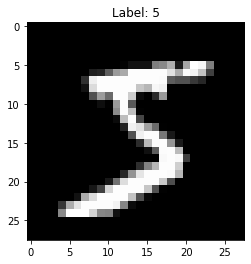

In [4]:
import pickle
import gzip

with gzip.open('neural-networks-and-deep-learning-master/data/mnist.pkl.gz', 'rb') as f:
    training_data, validation_data, test_data = pickle.load(f, encoding='latin1')

print(training_data[0].shape, training_data[1].shape)   # (50000, 784) (50000,)

first_image = training_data[0][0]
first_label = training_data[1][0]

# Reshape the first image to 28x28 pixels
image = first_image.reshape(28, 28)

# Display the image
plt.imshow(image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()


In [5]:
# Extract labels and training images from training_data
y_labels = training_data[1]
x_train = training_data[0].T

# Extract validation data
y_labels_val = validation_data[1]
x_val = validation_data[0].T

print(x_train.shape) # (728, 50000)
d = len(y_labels)

y_train = labels_to_onehot(y_labels)
y_val = labels_to_onehot(y_labels_val)


# Organize training data
train_data = (x_train, y_train)
val_data = (x_val, y_val)

(784, 50000)


Test Training run

Initial Training Loss 1.8572994182156373


  2%|▏         | 1/50 [00:01<01:35,  1.95s/it]

Loss at epoch e = 0 : 0.12733511275188417


  4%|▍         | 2/50 [00:03<01:27,  1.82s/it]

Loss at epoch e = 1 : 0.08909101897573278


  6%|▌         | 3/50 [00:05<01:26,  1.83s/it]

... (91 outputs left out)

 98%|█████████▊| 49/50 [01:28<00:01,  1.70s/it]

Loss at epoch e = 48 : 0.01229629272034161


100%|██████████| 50/50 [01:30<00:00,  1.81s/it]

Loss at epoch e = 49 : 0.012059742522648072


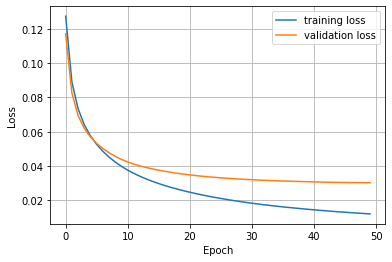

In [37]:
# Initialize a neural Network

spec = [784, 128, 32, 10]

NN = network(spec)

NN, train_losses, val_losses = train(NN, train_data, val_data, epochs=50, minibatch_size=50, eta=1, verbose=True)

plot_loss(train_losses, val_losses)

In [38]:
# Extract test set 
x_test = test_data[0].T
y_test = test_data[1]

# Compute predicted labels on the test set
pred_onehot = NN(x_test)[-1]
pred_labels = onehot_to_labels(pred_onehot)

print('labels shape', pred_labels.shape)

accuracy = np.mean(y_test == pred_labels)
print('accuracy on the test set', accuracy)

accuracy = compute_accuracy(NN, x_test, y_test)
print(accuracy)

labels shape (10000,)
accuracy on the test set 0.9603
0.9603


Initial Training Loss 2.0891766720678695


100%|██████████| 50/50 [01:29<00:00,  1.79s/it]


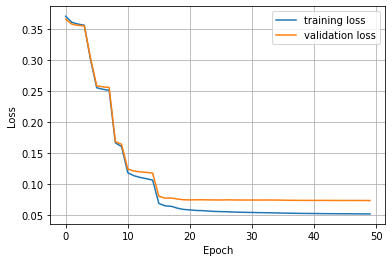

accuracy for lr = 10 : 0.8763
Initial Training Loss 2.0891766720678695


100%|██████████| 50/50 [01:29<00:00,  1.79s/it]


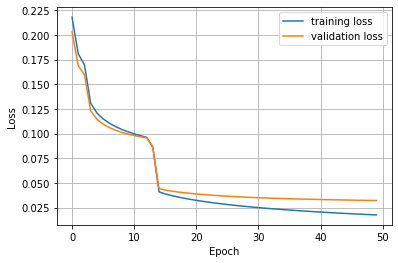

accuracy for lr = 1 : 0.9678
Initial Training Loss 2.0891766720678695


100%|██████████| 50/50 [01:38<00:00,  1.96s/it]


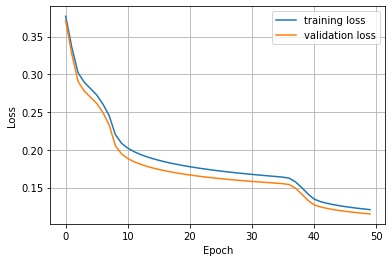

accuracy for lr = 0.1 : 0.8292
Initial Training Loss 2.0891766720678695


100%|██████████| 50/50 [01:43<00:00,  2.07s/it]


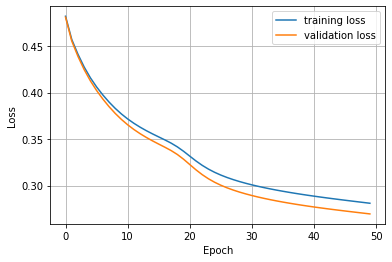

accuracy for lr = 0.01 : 0.5589
Initial Training Loss 2.0891766720678695


100%|██████████| 50/50 [01:43<00:00,  2.07s/it]


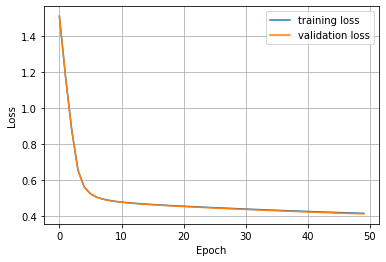

accuracy for lr = 0.001 : 0.3169
[0.8763 0.9678 0.8292 0.5589 0.3169]


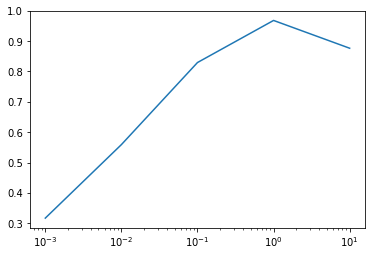

In [46]:
import copy
epochs = 50
etas = [10, 1, 0.1, 0.01, 0.001]
accuracies = np.zeros(5)

# Same initialization -> Same initial condition
NN = network([784, 128, 10])

for i in range(5):
    Li = copy.deepcopy(NN) 
    Li, train_losses, val_losses = train(Li, train_data, val_data, epochs=50, minibatch_size=50, eta=etas[i], verbose=False)
    plot_loss(train_losses, val_losses)
    accuracies[i] = compute_accuracy(Li, x_val, y_labels_val)
    print('accuracy for lr =', etas[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(etas, accuracies)

Now we can experiment with the size of the hidden layer

Initial Training Loss 1.5940623381925854


100%|██████████| 50/50 [00:45<00:00,  1.10it/s]


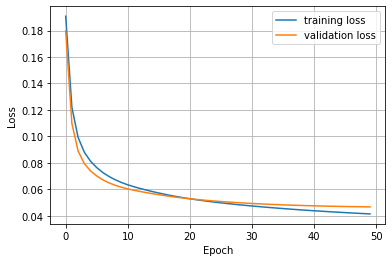

accuracy for hidden size = 16 : 0.9431
Initial Training Loss 2.068615596376251


100%|██████████| 50/50 [00:53<00:00,  1.07s/it]


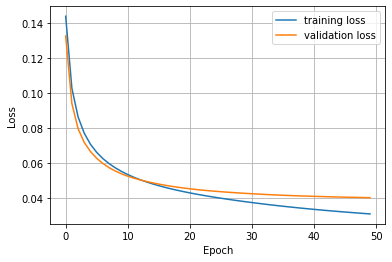

accuracy for hidden size = 32 : 0.9539
Initial Training Loss 2.1677012656772487


100%|██████████| 50/50 [01:03<00:00,  1.27s/it]


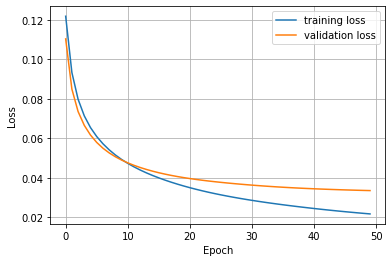

accuracy for hidden size = 64 : 0.9627
Initial Training Loss 1.8348973154975572


100%|██████████| 50/50 [01:37<00:00,  1.94s/it]


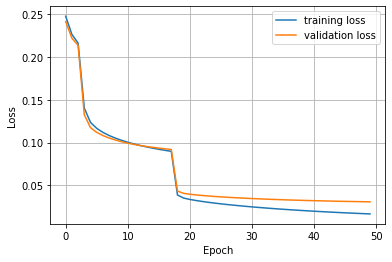

accuracy for hidden size = 128 : 0.968
Initial Training Loss 2.2743000998736873


100%|██████████| 50/50 [02:54<00:00,  3.49s/it]


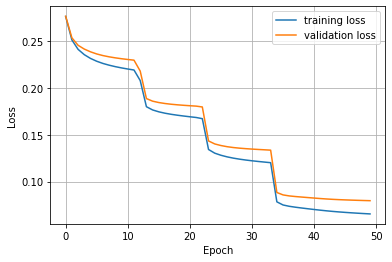

accuracy for hidden size = 256 : 0.8707
Initial Training Loss 2.844234410577478


100%|██████████| 50/50 [05:03<00:00,  6.06s/it]


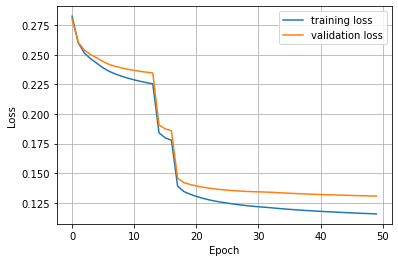

accuracy for hidden size = 512 : 0.7683
[0.9431 0.9539 0.9627 0.968  0.8707 0.7683]


NameError: name 'hs' is not defined

<Figure size 432x288 with 0 Axes>

In [50]:
import copy
epochs = 50
hiddens = [16, 32, 64, 128, 256, 512]
accuracies = np.zeros(6)

for i in range(6):
    h = hiddens[i]
    Li = network([784, h, 10])
    Li, train_losses, val_losses = train(Li, train_data, val_data, epochs=50, minibatch_size=50, eta=1, verbose=False)
    plot_loss(train_losses, val_losses)
    accuracies[i] = compute_accuracy(Li, x_val, y_labels_val)
    print('accuracy for hidden size =', h, ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(h, accuracies)